# Task 1 Reaudit Kaggle and retrain the four early models

Run this notebook first. It applies the extension's exact pHash/dHash/aspect-ratio graph to the **7,200-image** release, quarantines cross-label components, excludes training images linked to official Testing components and keeps complete graph components in training/validation/test. It retrains ViT-B/16, Swin-T, the original hybrid CNN and its bottleneck control.

You receive the requested historical-versus-new accuracy table. A paired **same-release, same-test** exact-only replay is enabled as a diagnostic because the historical hybrid result used the other 7,023-image release. The replay is deliberately leakage-prone and must not replace the audited headline results. No expected accuracy decrease is assumed. Kaggle duplicate groups are not verified patients.

## 1 Runtime dependencies

Use **Runtime → Change runtime type → GPU** for full image training and feature extraction. Run cells in order. The `paper` profile is the default. `smoke` is a short synthetic engineering test.

In [1]:
import os, sys, subprocess, importlib.util, importlib.metadata
from pathlib import Path
# Keep Colab's matching PyTorch/Torchvision pair; install missing helper packages only.
requirements = {'numpy':'numpy>=1.26,<3','pandas':'pandas>=2.2,<4','scipy':'scipy>=1.13,<2',
    'sklearn':'scikit-learn>=1.5,<2','matplotlib':'matplotlib>=3.8,<4','PIL':'Pillow>=10,<13',
    'h5py':'h5py>=3.10,<4','skimage':'scikit-image>=0.23,<1','imagehash':'ImageHash>=4.3,<5',
    'joblib':'joblib>=1.3,<2','requests':'requests>=2.31,<3','tqdm':'tqdm>=4.66,<5','tabulate':'tabulate>=0.9,<1'}
missing=[spec for name,spec in requirements.items() if importlib.util.find_spec(name) is None]
if missing: subprocess.check_call([sys.executable,'-m','pip','install','--quiet',*missing])
if importlib.util.find_spec('torch') is None or importlib.util.find_spec('torchvision') is None:
    subprocess.check_call([sys.executable,'-m','pip','install','--quiet','torch','torchvision','--index-url','https://download.pytorch.org/whl/cpu'])
import torch, torchvision
print('Python:',sys.version.split()[0], '| torch:',torch.__version__, '| torchvision:',torchvision.__version__)
print('CUDA:',torch.cuda.is_available())


Python: 3.13.15 | torch: 2.11.0+cu128 | torchvision: 0.26.0+cu128
CUDA: True


## 2 Configuration

The default settings run the full requested experiment. Reuse the same results root for notebooks 02, 03 and 04. Change the run name when you change scientific settings.

In [2]:
PROFILE = "paper"  # @param ['paper','smoke']
USE_DRIVE = os.getenv('MRI_USE_DRIVE', '1') == '1'  # @param {type:'boolean'}
RESULTS_ROOT = os.getenv('MRI_RESULTS_ROOT', '')  # empty = shared MyDrive folder in Colab
CACHE_ROOT = os.getenv('MRI_CACHE_ROOT', '')  # empty = local /content cache; reused across tasks
RUN_NAME = os.getenv('MRI_RUN_NAME', PROFILE + '_v1')
TASK4_RUN_NAME = os.getenv('MRI_TASK4_RUN_NAME', PROFILE + '_v1')
FIGSHARE_ROOT = os.getenv('MRI_FIGSHARE_ROOT', '')  # optional extracted native cjdata MAT folder
LEGACY_MANIFEST_CSV = os.getenv('MRI_LEGACY_MANIFEST_CSV', '')  # optional original saved partition CSV
AUDIT_NEAR = True
SPLIT_SEED = 20261023
CLASSES = ['glioma','meningioma','pituitary']
K = len(CLASSES)
CFG = dict(outer_folds=5,inner_folds=3,seeds=[13,29,47,71,101],epochs=40,patience=8,
    batch=128,feature_batch=32,slice_cap=8,learning_rates=[.01,.05],C_grid=[.03,.3,3.,30.],bootstrap=3000)
if PROFILE == 'smoke':
    CFG.update(outer_folds=2,inner_folds=2,seeds=[13],epochs=2,patience=2,batch=64,slice_cap=2,
        learning_rates=[.03],C_grid=[1.],bootstrap=50)
    USE_DRIVE=False
elif PROFILE!='paper':raise ValueError('Use paper or smoke.')
VIEWS = ['pixels32','resnet18']
# Smoke mode uses generated native MAT files and a deterministic random feature projection.
# It NEVER downloads MRI or produces scientific results.

TASK_ID=1
ENGINE_SIGNATURE='62c219a9695bb45f9faced3cf75413ba3e3b4eb8478bdcb463e6a15dc2b0c234'
CLASSES=['glioma','meningioma','notumor','pituitary'];K=len(CLASSES)
KAGGLE_ROOT=os.getenv('MRI_KAGGLE_ROOT','')
KAGGLE_ZIP=os.getenv('MRI_KAGGLE_ZIP','')
KAGGLE_HANDLE='masoudnickparvar/brain-tumor-mri-dataset'
STRICT_REFERENCE_AUDIT=True
RUN_MATCHED_REPLAY=True
MODEL_NAMES=['ViT_B16','Swin_T','HybridCNN','CNNControl']
CFG=dict(seeds=[42,13,29],epochs=20,patience=5,bootstrap=3000)
if PROFILE=='smoke':CFG.update(seeds=[42],epochs=1,patience=1,bootstrap=50)


### Shared data and statistics 1

Utilities: `json_default, canonical_json, digest`.

In [3]:
## Imports and reproducibility
import os, sys, json, math, time, random, hashlib, platform, copy, zipfile, shutil, warnings
from pathlib import Path
from collections import defaultdict
import numpy as np
import pandas as pd
import scipy.io
from scipy.fft import dctn
from scipy.special import softmax, logsumexp
from scipy.optimize import minimize_scalar
from scipy.ndimage import binary_fill_holes, binary_erosion, distance_transform_edt
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score, confusion_matrix, classification_report
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
import h5py, joblib, requests
from threadpoolctl import threadpool_limits
_THREAD_LIMITER=threadpool_limits(limits=min(4,os.cpu_count() or 1))
from tqdm.auto import tqdm
from IPython.display import display, Markdown

VERSION = 'faculty-revision-1.0'
def json_default(v):
    if isinstance(v, Path): return str(v)
    if isinstance(v, (np.integer, np.floating)): return v.item()
    if isinstance(v, np.ndarray): return v.tolist()
    raise TypeError(type(v).__name__)
def canonical_json(v): return json.dumps(v, sort_keys=True, default=json_default, allow_nan=False)
def digest(v): return hashlib.sha256(canonical_json(v).encode()).hexdigest()
def write_json(path, v):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    tmp=path.with_name(path.name+'.tmp'); tmp.write_text(json.dumps(v,indent=2,default=json_default),encoding='utf-8'); tmp.replace(path)
def file_hash(path, algorithm='sha256'):
    h=hashlib.new(algorithm)
    with open(path,'rb') as f:
        for b in iter(lambda:f.read(1024*1024),b''): h.update(b)
    return h.hexdigest()
def atomic_joblib(v,path):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True); tmp=path.with_name(path.name+'.tmp')
    joblib.dump(v,tmp,compress=3); tmp.replace(path)
def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    if 'torch' in sys.modules:
        import torch
        torch.manual_seed(seed)
        if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.benchmark=False; torch.backends.cudnn.deterministic=True
        torch.use_deterministic_algorithms(True,warn_only=True)
def savefig(fig, name):
    fig.tight_layout(); fig.savefig(OUT/(name+'.png'),dpi=180,bbox_inches='tight'); plt.show(); plt.close(fig)
def metric(y,p):
    y=np.asarray(y,int); p=np.asarray(p,float)
    assert p.shape==(len(y),K) and np.isfinite(p).all()
    assert np.allclose(p.sum(1),1,atol=1e-6)
    pred=p.argmax(1)
    ans=dict(accuracy=float(accuracy_score(y,pred)),balanced_accuracy=float(balanced_accuracy_score(y,pred)),
             macro_f1=float(f1_score(y,pred,labels=np.arange(K),average='macro',zero_division=0)),
             nll=float(-np.log(np.clip(p[np.arange(len(y)),y],1e-15,1)).mean()))
    try: ans['macro_auc']=float(roc_auc_score(y,p,multi_class='ovr',average='macro',labels=np.arange(K)))
    except ValueError: ans['macro_auc']=float('nan')
    return ans

def aggregate(frame, indices, p):
    sub=frame.iloc[np.asarray(indices)][['patient_id','label_id']].copy().reset_index(drop=True)
    for j in range(K): sub[f'p{j}']=p[:,j]
    assert sub.groupby('patient_id').label_id.nunique().max()==1
    return sub.groupby('patient_id',sort=True).agg({'label_id':'first',**{f'p{j}':'mean' for j in range(K)}}).reset_index()
def pcols(table): return table[[f'p{j}' for j in range(K)]].to_numpy(float)
def patient_weights(frame,idx):
    sub=frame.iloc[idx]; w=1/sub.patient_id.map(sub.patient_id.value_counts()).to_numpy(float)
    # Equal total mass for every class, and every patient within a class.
    for y in range(K): w[sub.label_id.to_numpy()==y]/=w[sub.label_id.to_numpy()==y].sum()
    return w/w.mean()


### Shared data and statistics 2

Utilities: `balanced_slice_weights, stratified_resample, f1_fast`.

In [4]:
def balanced_slice_weights(y):
    n=np.bincount(np.asarray(y,int),minlength=K); return len(y)/(K*n)
def stratified_resample(y,rng):
    return np.concatenate([rng.choice(np.flatnonzero(y==c),size=np.sum(y==c),replace=True) for c in np.unique(y)])
def f1_fast(y,pred):
    cm=np.bincount(K*np.asarray(y,int)+np.asarray(pred,int),minlength=K*K).reshape(K,K)
    den=cm.sum(0)+cm.sum(1); return float(np.divide(2*np.diag(cm),den,out=np.zeros(K),where=den!=0).mean())
def seed_patient_interval(y, a, b=None, n_boot=3000, seed=341, groups=None):
    # a,b: [seed, patient, class]. Seeds are paired blocks, never extra patients.
    a=np.asarray(a); b=None if b is None else np.asarray(b)
    assert a.ndim==3 and a.shape[1:]==(len(y),K)
    if b is not None: assert a.shape==b.shape
    pred_a=a.argmax(2); pred_b=None if b is None else b.argmax(2)
    def statistic(si,ii):
        values=[f1_fast(y[ii],pred_a[s,ii])-(0 if pred_b is None else f1_fast(y[ii],pred_b[s,ii])) for s in si]
        return float(np.mean(values))
    rng=np.random.default_rng(seed); all_s=np.arange(len(a)); all_i=np.arange(len(y))
    estimate=statistic(all_s,all_i); fixed=[]; joint=[]
    if groups is not None:
        group_array=np.asarray(groups); ug=np.unique(group_array)
        # If duplicate links join patients, resample complete linked clusters.
        def draw():
            while True:
                sampled=rng.choice(ug,len(ug),replace=True)
                ii=np.concatenate([np.flatnonzero(group_array==g) for g in sampled])
                if len(np.unique(y[ii]))==K:return ii
    else:
        def draw(): return stratified_resample(np.asarray(y),rng)
    for _ in range(n_boot):
        ii=draw(); fixed.append(statistic(all_s,ii)); joint.append(statistic(rng.choice(all_s,len(a),replace=True),ii))
    lo,hi=np.quantile(joint,[.025,.975]); fl,fh=np.quantile(fixed,[.025,.975])
    return dict(estimate=estimate,ci_low=float(lo),ci_high=float(hi),patient_only_low=float(fl),patient_only_high=float(fh),
                n_patients=len(y),n_seeds=len(a),n_boot=n_boot,
                interval_scope='paired seed and patient/linked-cluster resampling conditional on fitted outer folds; excludes full refitting and site variance')

def holm(values):
    p=np.asarray(values,float); order=np.argsort(p); ans=np.empty(len(p)); running=0.
    for i,j in enumerate(order): running=max(running,(len(p)-i)*p[j]); ans[j]=min(1.,running)
    return ans

def paired_permutation(y,a,b,reps=1999,seed=774):
    rng=np.random.default_rng(seed); observed=np.mean([f1_fast(y,x.argmax(1))-f1_fast(y,z.argmax(1)) for x,z in zip(a,b)])
    extreme=0
    for _ in range(reps):
        swap=rng.integers(0,2,len(y)).astype(bool)
        aa=np.where(swap[None,:,None],b,a); bb=np.where(swap[None,:,None],a,b)
        value=np.mean([f1_fast(y,x.argmax(1))-f1_fast(y,z.argmax(1)) for x,z in zip(aa,bb)])
        extreme+=abs(value)>=abs(observed)-1e-12
    return (extreme+1)/(reps+1)

def package_outputs(out, name):
    target=out.parent/(name+'.zip')
    with zipfile.ZipFile(target,'w',zipfile.ZIP_DEFLATED) as z:
        for p in sorted(out.rglob('*')):
            if p.is_file() and p.suffix not in {'.tmp','.part'}:
                # Large image-model weights remain in the Drive checkpoint folders.
                if name.startswith('Task1_') and p.suffix=='.pt':continue
                z.write(p,p.relative_to(out.parent))
    print('Results bundle:',target)
    return target


### Shared data and statistics 3

Utilities: `download_file, safe_extract, figshare_files`.

In [5]:
## Verified downloads and native Figshare reader

def download_file(url,path,md5=None):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    if path.is_file() and path.stat().st_size and (not md5 or file_hash(path,'md5')==md5):return path
    tmp=path.with_name(path.name+'.part')
    for attempt in range(4):
        try:
            fresh=url
            if 'figshare.com/' in url:fresh=url+('&' if '?' in url else '?')+'revision_time='+str(time.time_ns())
            with requests.get(fresh,stream=True,timeout=(30,120)) as r:
                r.raise_for_status()
                with open(tmp,'wb') as f:
                    for b in r.iter_content(1024*1024):
                        if b:f.write(b)
            if tmp.stat().st_size==0 or (md5 and file_hash(tmp,'md5')!=md5):raise ValueError('Empty download or publisher checksum mismatch')
            tmp.replace(path); return path
        except (requests.RequestException,OSError,ValueError) as e:
            tmp.unlink(missing_ok=True)
            if attempt==3: raise RuntimeError(f'Download failed for {path.name}. Supply an extracted local dataset root in the configuration.') from e
            time.sleep(min(2**attempt,8))
def safe_extract(archive,root):
    root=Path(root).resolve(); root.mkdir(parents=True,exist_ok=True)
    with zipfile.ZipFile(archive) as z:
        for item in z.infolist():
            p=(root/item.filename).resolve()
            if p!=root and root not in p.parents:raise ValueError('Unsafe ZIP member')
            if (item.external_attr>>16)&0o170000==0o120000:raise ValueError('Symlink in ZIP')
        z.extractall(root)
def figshare_files():
    if FIGSHARE_ROOT:
        root=Path(FIGSHARE_ROOT).expanduser().resolve()
        if not root.is_dir():raise FileNotFoundError(root)
    else:
        root=CACHE/'figshare_1512427_v8'; root.mkdir(parents=True,exist_ok=True)
        meta=root/'publisher_metadata.json'
        try:
            r=requests.get('https://api.figshare.com/v2/articles/1512427/versions/8',timeout=(30,90));r.raise_for_status();article=r.json();write_json(meta,article)
        except (requests.RequestException,ValueError):
            if not meta.exists():raise
            article=json.loads(meta.read_text());print('Using cached version 8 metadata with checksum validation.')
        for f in article['files']:
            if not f['name'].lower().endswith('.zip'):continue
            archive=download_file(f['download_url'],root/Path(f['name']).name,f.get('computed_md5') or f.get('supplied_md5'))
            marker=archive.with_suffix('.extracted.json'); sha=file_hash(archive)
            with zipfile.ZipFile(archive) as z: members=[x for x in z.infolist() if not x.is_dir()]
            ok=marker.exists() and json.loads(marker.read_text()).get('sha256')==sha
            ok=ok and all((root/x.filename).is_file() and (root/x.filename).stat().st_size==x.file_size for x in members)
            if not ok:safe_extract(archive,root);write_json(marker,{'sha256':sha})
    paths=sorted(p for p in root.rglob('*.mat') if p.stem.isdigit())
    if not paths: raise FileNotFoundError('No numbered native cjdata MAT files. Use the original Figshare release, not a JPG conversion.')
    return root,paths

def decode_pid(value):
    if isinstance(value,bytes): return value.decode().strip()
    if isinstance(value,str):return value.strip()
    a=np.asarray(value).ravel()
    if a.dtype.kind in 'US':return ''.join(x.decode() if isinstance(x,bytes) else str(x) for x in a).strip()
    if a.dtype.kind in 'iuf' and len(a)>1:return ''.join(chr(int(x)) for x in a if int(x)).strip()
    return ''.join(str(x) for x in a).strip()


### Shared data and statistics 4

Utilities: `read_mat, normalize_image, resize_float`.

In [6]:
def read_mat(path):
    if h5py.is_hdf5(path):
        with h5py.File(path,'r') as f:
            g=f['cjdata']
            def value(key):
                v=g[key]
                if h5py.check_dtype(ref=v.dtype) is not None:
                    refs=np.asarray(v).ravel()
                    if len(refs)!=1:raise ValueError('Unexpected multiple MATLAB references')
                    return np.asarray(f[refs[0]])
                return np.asarray(v)
            image=value('image').T; rawmask=value('tumorMask').T if 'tumorMask' in g else None
            pid=decode_pid(value('PID')); label=int(value('label').squeeze()); fields=list(g.keys())
    else:
        g=scipy.io.loadmat(path,simplify_cells=True)['cjdata']
        image=np.asarray(g['image']);rawmask=np.asarray(g['tumorMask']) if 'tumorMask' in g else None
        pid=decode_pid(g['PID']);label=int(np.asarray(g['label']).squeeze());fields=list(g)
    if label not in [1,2,3] or not pid or image.ndim!=2 or not np.isfinite(image).all():raise ValueError('Invalid cjdata '+str(path))
    if rawmask is None:mask=None
    else:
        if rawmask.shape!=image.shape or not np.isfinite(rawmask).all():raise ValueError('Mask shape or numeric error '+str(path))
        if not set(np.unique(rawmask)).issubset({0,1,False,True}):raise ValueError('Mask must be binary '+str(path))
        mask=rawmask.astype(bool)
    return image,mask,'cheng::'+pid,{1:'meningioma',2:'glioma',3:'pituitary'}[label],fields

def normalize_image(x):
    x=np.asarray(x,np.float32);lo,hi=np.percentile(x,[1,99]);return np.clip((x-lo)/max(float(hi-lo),1e-6),0,1)
def resize_float(x,side):return np.asarray(Image.fromarray(np.asarray(x,np.float32)).resize((side,side),Image.Resampling.BILINEAR),np.float32)

def fixture_figshare():
    root=CACHE/'synthetic_native';root.mkdir(parents=True,exist_ok=True)
    rng=np.random.default_rng(811); paths=[]; yy,xx=np.mgrid[:40,:40]
    for c,label in enumerate(['glioma','meningioma','pituitary']):
        for patient in range(12):
            for sl in range(2):
                brain=((xx-20)/16)**2+((yy-20)/18)**2<1
                mask=(xx-(12+5*c))**2+(yy-19)**2<(4+c)**2
                x=np.maximum(0,rng.normal(.08,.03,(40,40)))+brain*.25+mask*.4
                image=(np.clip(x,0,1)*65535).astype(np.uint16)
                p=root/f'{c*1000+patient*2+sl+1}.mat'
                pid=f'synthetic_{label}_{patient:03d}'
                # Mix both native MAT reader paths, including HDF5 MATLAB orientation.
                lab={'meningioma':1,'glioma':2,'pituitary':3}[label]
                if sl%2==0:
                    scipy.io.savemat(p,{'cjdata':dict(image=image,tumorMask=mask.astype(np.uint8),PID=pid,label=lab)})
                else:
                    with h5py.File(p,'w') as f:
                        g=f.create_group('cjdata');g['image']=image.T;g['tumorMask']=mask.T.astype(np.uint8)
                        g['PID']=np.array([ord(t) for t in pid],np.uint16)[:,None];g['label']=np.array([[lab]])
                paths.append(p)
    return root,sorted(paths)


### Shared data and statistics 5

Utilities: `native_manifest, DSU, BKTree`.

In [7]:
def native_manifest():
    root,paths=fixture_figshare() if PROFILE=='smoke' else figshare_files()
    records=[]
    for p in tqdm(paths,desc='Validate native images, IDs and masks'):
        x,m,pid,label,fields=read_mat(p)
        records.append(dict(sample_id=p.stem,relative_path=p.relative_to(root).as_posix(),path=str(p.resolve()),
            patient_id=pid,label=label,label_id=CLASSES.index(label),height=x.shape[0],width=x.shape[1],
            mask_present=m is not None,mask_pixels=int(m.sum()) if m is not None else 0,
            file_sha256=file_hash(p),pixel_sha256=hashlib.sha256(str((x.shape,str(x.dtype))).encode()+x.tobytes()).hexdigest()))
    frame=pd.DataFrame(records).sort_values('relative_path').reset_index(drop=True)
    assert frame.sample_id.is_unique and frame.groupby('patient_id').label_id.nunique().max()==1
    if PROFILE!='smoke':
        assert len(frame)==3064 and frame.patient_id.nunique()==233, 'Wrong/incomplete Figshare release; expected 3,064 slices and 233 patients.'
        assert frame.groupby('label').size().to_dict()=={'glioma':1426,'meningioma':708,'pituitary':930}
    return frame

## Fold construction, EDA and independent frozen features
class DSU:
    def __init__(self,n):self.p=list(range(n))
    def find(self,i):
        while self.p[i]!=i:self.p[i]=self.p[self.p[i]];i=self.p[i]
        return i
    def union(self,a,b):
        a,b=self.find(a),self.find(b)
        if a!=b:self.p[max(a,b)]=min(a,b)
class BKTree:
    def __init__(self):self.root=None
    def add(self,v,i):
        if self.root is None:self.root=[v,[i],{}];return
        n=self.root
        while True:
            d=(n[0]^v).bit_count()
            if d==0:n[1].append(i);return
            if d not in n[2]:n[2][d]=[v,[i],{}];return
            n=n[2][d]
    def query(self,v,r):
        found=[];stack=[] if self.root is None else [self.root]
        while stack:
            n=stack.pop();d=(n[0]^v).bit_count()
            if d<=r:found.extend(n[1])
            stack.extend(child for k,child in n[2].items() if d-r<=k<=d+r)
        return found

def patient_duplicate_links(frame):
    # Patient identity is the endpoint; duplicate links only constrain splitting.
    import imagehash
    from skimage.metrics import structural_similarity
    units=sorted(frame.patient_id.unique());lookup={x:i for i,x in enumerate(units)};uf=DSU(len(units));edges=[]
    for _,ids in frame.groupby('pixel_sha256').groups.items():
        ids=list(ids)
        for j in ids[1:]:
            a,b=frame.iloc[ids[0]],frame.iloc[j];uf.union(lookup[a.patient_id],lookup[b.patient_id])
            if a.patient_id!=b.patient_id:edges.append(dict(a=a.sample_id,b=b.sample_id,kind='exact',ssim=1.))
    if AUDIT_NEAR:
        tree=BKTree();thumb=[]; hashes=[]
        for i,row in tqdm(enumerate(frame.itertuples()),total=len(frame),desc='Cross-patient duplicate audit'):
            small=(resize_float(normalize_image(read_mat(row.path)[0]),64)*255).astype(np.uint8)
            h=int(str(imagehash.phash(Image.fromarray(small))),16)
            for j in tree.query(h,3):
                if row.patient_id==frame.iloc[j].patient_id:continue
                s=float(structural_similarity(small,thumb[j],data_range=255))
                if s>=.985:
                    uf.union(lookup[row.patient_id],lookup[frame.iloc[j].patient_id]);edges.append(dict(a=row.sample_id,b=frame.iloc[j].sample_id,kind='near',ssim=s))
            thumb.append(small);hashes.append(h);tree.add(h,i)
    groups={pid:'link_'+digest(sorted(x for x in units if uf.find(lookup[x])==uf.find(lookup[pid])))[:16] for pid in units}
    result=frame.copy();result['split_group']=result.patient_id.map(groups)
    pd.DataFrame(edges,columns=['a','b','kind','ssim']).to_csv(OUT/'cross_patient_duplicate_links.csv',index=False)
    return result


### Shared data and statistics 6

Utilities: `grouped_patient_folds, make_nested_plan, idx_for`.

In [8]:
def grouped_patient_folds(frame,patient_ids,n,seed):
    tab=frame[frame.patient_id.isin(patient_ids)][['patient_id','label_id','split_group']].drop_duplicates().sort_values('patient_id').reset_index(drop=True)
    if (tab.groupby('label_id').size()<n).any():raise ValueError('Not enough patients per class for requested folds')
    if tab.split_group.nunique()==len(tab):
        splitter=StratifiedKFold(n_splits=n,shuffle=True,random_state=seed);iterator=splitter.split(tab,tab.label_id)
    else:
        splitter=StratifiedGroupKFold(n_splits=n,shuffle=True,random_state=seed);iterator=splitter.split(tab,tab.label_id,tab.split_group)
    folds=[]
    for tr,va in iterator:
        a,b=tab.iloc[tr],tab.iloc[va]
        assert not set(a.split_group)&set(b.split_group)
        if set(a.label_id)!=set(range(K)) or set(b.label_id)!=set(range(K)):raise ValueError('Fold lost a class after duplicate grouping; review the linkage audit before changing protocol.')
        folds.append((a.patient_id.tolist(),b.patient_id.tolist()))
    return folds

def make_nested_plan(frame):
    plans=[]
    for fold,(dev,test) in enumerate(grouped_patient_folds(frame,frame.patient_id.unique(),CFG['outer_folds'],SPLIT_SEED)):
        inner=[dict(train_patients=a,valid_patients=b) for a,b in grouped_patient_folds(frame,dev,CFG['inner_folds'],SPLIT_SEED+100+fold)]
        plans.append(dict(fold=fold,development_patients=dev,test_patients=test,inner=inner))
    tests=[p for item in plans for p in item['test_patients']]
    assert len(tests)==len(set(tests))==frame.patient_id.nunique()
    return plans

def idx_for(frame,patients):return np.flatnonzero(frame.patient_id.isin(set(patients)).to_numpy())
def cap_training(frame,indices,seed):
    rng=np.random.default_rng(seed);keep=[]
    for _,s in frame.iloc[indices].groupby('patient_id',sort=True):
        keep.extend(rng.choice(s.index.to_numpy(),min(len(s),CFG['slice_cap']),replace=False))
    return np.asarray(sorted(keep),int)

def dataset_eda(frame):
    counts=pd.DataFrame({'slices':frame.groupby('label').size(),'patients':frame.groupby('label').patient_id.nunique()})
    counts.to_csv(OUT/'eda_class_counts.csv');display(counts)
    fig,axes=plt.subplots(1,3,figsize=(13,3.5));counts.plot.bar(ax=axes[0],rot=25)
    frame.groupby('patient_id').size().plot.hist(bins=20,ax=axes[1]);axes[1].set_title('Slices per patient')
    axes[2].scatter(frame.width,frame.height,s=5,alpha=.3);axes[2].set_title('Native dimensions');savefig(fig,'eda_counts_dimensions')
    fig,axes=plt.subplots(K,3,figsize=(8,K*2.5),squeeze=False)
    for c in range(K):
        for ax,(_,r) in zip(axes[c],frame[frame.label_id==c].head(3).iterrows()):
            x,m,*_=read_mat(r.path);ax.imshow(normalize_image(x),cmap='gray')
            if m is not None and m.any():ax.contour(m,levels=[.5],colors=['lime'],linewidths=.7)
            ax.set_title(CLASSES[c]);ax.axis('off')
    savefig(fig,'eda_native_mask_overlays')

_BACKBONE=None

def resnet_features(images):
    global _BACKBONE
    import torch
    from torchvision import models
    if _BACKBONE is None:
        device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        _BACKBONE=models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        _BACKBONE.fc=torch.nn.Identity();_BACKBONE.eval().to(device)
        for p in _BACKBONE.parameters():p.requires_grad_(False)
    device=next(_BACKBONE.parameters()).device;results=[]
    mean=torch.tensor([.485,.456,.406],device=device)[None,:,None,None]
    std=torch.tensor([.229,.224,.225],device=device)[None,:,None,None]
    with torch.inference_mode():
        for start in range(0,len(images),CFG['feature_batch']):
            batch=np.stack([resize_float(im,224) for im in images[start:start+CFG['feature_batch']]])
            x=torch.as_tensor(batch[:,None],device=device).repeat(1,3,1,1);x=(x-mean)/std
            results.append(_BACKBONE(x).float().cpu().numpy())
    return np.concatenate(results)


### Shared data and statistics 7

Utilities: `feature_arrays`.

In [9]:
def feature_arrays(frame):
    identity=digest(dict(images=frame[['sample_id','file_sha256']].to_dict('records'),version=VERSION,fixture=PROFILE=='smoke',resnet='IMAGENET1K_V1',normalization='percentile1_99',resize='bilinear_direct'))
    path=CACHE/f'figshare_features_{identity[:16]}.joblib'
    if path.exists():return joblib.load(path)
    ims=[normalize_image(read_mat(r.path)[0]) for r in tqdm(frame.itertuples(),total=len(frame),desc='Per-image normalization')]
    pix=np.stack([resize_float(im,32).ravel() for im in ims]).astype(np.float64)
    if PROFILE=='smoke':
        # No network/ImageNet weights during synthetic code tests. Never scientific results.
        projection=np.random.default_rng(411).normal(size=(pix.shape[1],64))/np.sqrt(pix.shape[1]);rich=pix@projection
    else:rich=resnet_features(ims).astype(np.float64)
    ans=dict(pixels32=pix,resnet18=rich,feature_identity=identity);atomic_joblib(ans,path);return ans


## 3 Output location and environment

In [12]:
BASE = Path('/content') if Path('/content').is_dir() else Path.cwd()

def _can_mount_drive():
    # Real Colab VMs have this file; google.colab alone being importable isn't enough
    return importlib.util.find_spec('google.colab') is not None and os.path.exists('/var/colab/hostname')

if USE_DRIVE:
    if not _can_mount_drive():
        print('Drive mounting is unsupported here: saving to the local result directory instead.')
        USE_DRIVE = False
    else:
        from google.colab import drive
        drive.mount('/content/drive', force_remount=False)
        if not Path('/content/drive/MyDrive').is_dir():
            raise RuntimeError('Drive did not mount. Reconnect it, or set USE_DRIVE=False and download the result ZIP.')
        if not RESULTS_ROOT:
            RESULTS_ROOT = '/content/drive/MyDrive/Brain_MRI_Faculty_Revision'

ROOT = Path(RESULTS_ROOT) if RESULTS_ROOT else BASE / 'Brain_MRI_Faculty_Revision'
CACHE = Path(CACHE_ROOT) if CACHE_ROOT else BASE / 'brain_mri_faculty_cache'

Drive mounting is unsupported here: saving to the local result directory instead.


### Image audit and training 1

Utilities: `kaggle_fixture, obtain_kaggle, scan_kaggle`.

In [13]:
## Download the 7200-image release or use a local copy

def kaggle_fixture():
    root=CACHE/'synthetic_kaggle';root.mkdir(parents=True,exist_ok=True);rng=np.random.default_rng(917)
    for split,n in [('Training',12),('Testing',5)]:
        for c,label in enumerate(CLASSES):
            d=root/split/label;d.mkdir(parents=True,exist_ok=True)
            for i in range(n):
                x=rng.integers(0,210,(48,50+c,3),dtype=np.uint8);x[12:25,5+c*5:13+c*5]=245
                Image.fromarray(x).save(d/f'{i:03d}.png')
    # Exact copies plus mild near copies of test images in training.
    for label in CLASSES:
        shutil.copy2(root/'Testing'/label/'000.png',root/'Training'/label/'exact_test_copy.png')
        with Image.open(root/'Testing'/label/'001.png') as im:
            x=np.asarray(im).copy();x[0,0]=np.maximum(0,x[0,0].astype(int)-1)
            Image.fromarray(x).save(root/'Training'/label/'near_test_copy.png')
    return root

def obtain_kaggle():
    if PROFILE=='smoke':return kaggle_fixture()
    if KAGGLE_ROOT:
        root=Path(KAGGLE_ROOT).expanduser().resolve()
        if not root.is_dir():raise FileNotFoundError(root)
        return root
    if KAGGLE_ZIP:
        root=CACHE/'kaggle_extracted';safe_extract(KAGGLE_ZIP,root);return root
    archive=download_file('https://www.kaggle.com/api/v1/datasets/download/'+KAGGLE_HANDLE,CACHE/'brain_tumor_7200.zip')
    if not zipfile.is_zipfile(archive):raise ValueError('Kaggle did not return a ZIP. Set KAGGLE_ZIP or KAGGLE_ROOT to the exact release used by the extension.')
    root=CACHE/'kaggle_extracted';marker=root/'extracted_sha256.txt';sha=file_hash(archive)
    if not marker.exists() or marker.read_text()!=sha:
        safe_extract(archive,root);marker.write_text(sha)
    return root.resolve()

def scan_kaggle(root):
    records=[];failures=[]
    for p in tqdm(sorted(root.rglob('*')),desc='Audit native Kaggle pixels'):
        if p.suffix.lower() not in {'.jpg','.jpeg','.png','.bmp','.tif','.tiff'}:continue
        parts=p.relative_to(root).parts;label=next((x for x in reversed(parts[:-1]) if x.lower().replace('_','').replace(' ','') in CLASSES),None)
        if label is None:continue
        label=label.lower().replace('_','').replace(' ','')
        split=next((x.lower() for x in parts[:-1] if x.lower() in ['training','testing']),None)
        if split is None:raise ValueError('A class image is outside Training/Testing: '+str(p))
        try:
            with Image.open(p) as opened:
                im=ImageOps.exif_transpose(opened).convert('RGB');rgb=np.asarray(im);gray=im.convert('L');w,h=im.size
                exact=hashlib.sha256(np.asarray(rgb.shape,dtype=np.int64).tobytes()+rgb.tobytes()).hexdigest()
                small=np.asarray(gray.resize((32,32),Image.Resampling.LANCZOS),float)
                low=dctn(small,norm='ortho')[:8,:8].ravel();bits=low>np.median(low[1:]);bits[0]=False
                ph=sum(int(b)<<i for i,b in enumerate(bits))
                ds=np.asarray(gray.resize((9,8),Image.Resampling.BILINEAR));dh=sum(int(b)<<i for i,b in enumerate((ds[:,1:]>ds[:,:-1]).ravel()))
            records.append(dict(sample_id=p.relative_to(root).as_posix(),path=str(p),relative_path=p.relative_to(root).as_posix(),
                label=label,label_id=CLASSES.index(label),original_split=split.title(),pixel_sha256=exact,
                phash=f'{ph:016x}',dhash=f'{dh:016x}',width=w,height=h,file_sha256=file_hash(p)))
        except Exception as e:failures.append(dict(path=str(p),error=str(e)))
    f=pd.DataFrame(records).sort_values('relative_path').reset_index(drop=True)
    pd.DataFrame(failures,columns=['path','error']).to_csv(OUT/'decode_failures.csv',index=False)
    if failures:raise ValueError('Unreadable images found; see decode_failures.csv rather than silently dropping them.')
    if PROFILE!='smoke':
        counts=pd.crosstab(f.label,f.original_split)
        assert len(f)==7200 and (counts['Training']==1400).all() and (counts['Testing']==400).all(), 'This is not the audited 7200-image release. The 7023-image v1 release is a different benchmark. Set KAGGLE_ROOT to the intended 7200-image release.'
    return f


### Image audit and training 2

Utilities: `graph_audit`.

In [14]:
def graph_audit(raw):
    f=raw.copy().reset_index(drop=True);uf=DSU(len(f));edges=[]
    for _,ix in f.groupby('pixel_sha256',sort=False).groups.items():
        ix=list(ix)
        for j in ix[1:]:uf.union(ix[0],j);edges.append(dict(a=ix[0],b=j,kind='exact'))
    tree=BKTree();ph=[int(s,16) for s in f.phash];dh=[int(s,16) for s in f.dhash];aspect=(f.width/f.height).to_numpy()
    for i in tqdm(range(len(f)),desc='Extension near-duplicate graph'):
        for j in tree.query(ph[i],4):
            if (dh[i]^dh[j]).bit_count()<=6 and abs(math.log(aspect[i]/aspect[j]))<=.05:
                uf.union(i,j);edges.append(dict(a=j,b=i,kind='near'))
        tree.add(ph[i],i)
    comp=defaultdict(list)
    for i in range(len(f)):comp[uf.find(i)].append(i)
    groups={r:'group_'+hashlib.sha256('|'.join(sorted(f.loc[ix,'relative_path'])).encode()).hexdigest()[:16] for r,ix in comp.items()}
    f['split_group']=[groups[uf.find(i)] for i in range(len(f))]
    mixed=set(f.groupby('split_group').label_id.nunique().loc[lambda s:s>1].index)
    quarantine=f[f.split_group.isin(mixed)].copy();c=f[~f.split_group.isin(mixed)].copy()
    c['_priority']=(c.original_split!='Testing').astype(int)
    exact=c.sort_values(['_priority','relative_path']).drop_duplicates('pixel_sha256',keep='first').drop(columns='_priority')
    test_groups=set(exact.loc[exact.original_split=='Testing','split_group'])
    crossed=(exact.original_split=='Training')&exact.split_group.isin(test_groups)
    removed=exact[crossed].copy();clean=exact[~crossed].sort_values('relative_path').reset_index(drop=True)
    audit=dict(raw_images=len(f),quarantined_cross_label_images=len(quarantine),exact_redundant_images=len(c)-len(exact),
        cross_boundary_training_images_removed=len(removed),retained_images=len(clean),groups=int(clean.split_group.nunique()),
        thresholds=dict(phash=4,dhash=6,absolute_log_aspect=.05),patient_independence_verified=False)
    f.to_csv(OUT/'raw_graph_manifest.csv',index=False);quarantine.to_csv(OUT/'quarantined_cross_label.csv',index=False)
    removed.to_csv(OUT/'cross_boundary_training_images_removed.csv',index=False);clean.to_csv(OUT/'audited_manifest.csv',index=False)
    pd.DataFrame([dict(a=f.iloc[e['a']].sample_id,b=f.iloc[e['b']].sample_id,kind=e['kind']) for e in edges]).to_csv(OUT/'duplicate_edges.csv',index=False)
    write_json(OUT/'duplicate_audit.json',audit)
    if PROFILE!='smoke' and STRICT_REFERENCE_AUDIT:
        expected={'quarantined_cross_label_images':34,'exact_redundant_images':317,'cross_boundary_training_images_removed':957,'retained_images':5892,'groups':5091}
        diff={k:dict(expected=v,observed=audit[k]) for k,v in expected.items() if audit[k]!=v}
        if diff:write_json(OUT/'reference_audit_mismatch.json',diff);raise ValueError('Audit counts differ from the submitted extension. Inspect reference_audit_mismatch.json and supply the exact release; thresholds have not been changed to force a match.')
    return f,clean,exact,audit


### Image audit and training 3

Utilities: `create_kaggle_splits, torch_gate, ry`.

In [15]:
## One shared audited split for all four models

def create_kaggle_splits(graph,clean,exact):
    dev=clean[clean.original_split=='Training'].copy();test=clean[clean.original_split=='Testing'].copy()
    group=dev[['split_group','label_id']].drop_duplicates().sort_values('split_group')
    tr,va=train_test_split(group,test_size=.20,stratify=group.label_id,random_state=42)
    train=dev[dev.split_group.isin(tr.split_group)].copy();valid=dev[dev.split_group.isin(va.split_group)].copy()
    # A paired diagnostic replay on the SAME release and SAME held-out test/validation.
    # It restores near-linked training examples excluded by the audited graph; never a headline result.
    replay=exact[(exact.original_split=='Training')&~exact.split_group.isin(set(valid.split_group))].copy()
    conditions={'audited':dict(train=train,validation=valid,test=test)}
    if RUN_MATCHED_REPLAY:conditions['exact_only_replay']=dict(train=replay,validation=valid,test=test)
    for condition,splits in conditions.items():
        for split,frame in splits.items():
            frame=frame.sort_values('relative_path').reset_index(drop=True)
            if PROFILE=='smoke':frame=frame.groupby('label_id',group_keys=False).head(2 if split=='train' else 1).reset_index(drop=True)
            conditions[condition][split]=frame;frame.to_csv(OUT/f'{condition}_{split}_manifest.csv',index=False)
        for a,b in [('train','validation'),('train','test'),('validation','test')]:
            assert not set(conditions[condition][a].pixel_sha256)&set(conditions[condition][b].pixel_sha256)
            if condition=='audited':assert not set(conditions[condition][a].split_group)&set(conditions[condition][b].split_group)
    assert all(set(x['test'].sample_id)==set(conditions['audited']['test'].sample_id) for x in conditions.values())
    return conditions

## Models preserving the original CNN and transformer architectures
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models,transforms
from torchvision.transforms import InterpolationMode
from contextlib import nullcontext
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(min(4,os.cpu_count() or 1))

def torch_gate(state,gate,q,n):
    a=state.reshape(-1,2**q,2,2**(n-q-1))
    return torch.einsum('ab,mlbr->mlar',gate,a).reshape(-1,2**n)
def ry(theta):
    c,s=torch.cos(theta/2),torch.sin(theta/2)
    return torch.stack([torch.stack([c,-s]),torch.stack([s,c])]).to(torch.complex128)
def rz(theta):return torch.diag(torch.stack([torch.exp(-.5j*theta),torch.exp(.5j*theta)]))
class SixQubitLayer(nn.Module):
    def __init__(self):
        super().__init__();self.weights=nn.Parameter(.1*torch.randn(3,6,2))
        ids=torch.arange(64);self.register_buffer('signs',(1-2*((ids[None,:]>>(5-torch.arange(6)[:,None]))&1)).double())
        for q in range(6):self.register_buffer(f'perm_{q}',ids^(((ids>>(5-q))&1)<<(5-(q+1)%6)))
    def forward(self,x):
        # Exact analytic, differentiable statevector; same RY input, RY/RZ gates and CNOT ring as the original PennyLane layer.
        # The batch and circuit stay on the model device, avoiding CPU/GPU graph breaks.
        x=x.double();state=torch.ones((len(x),1),dtype=torch.complex128,device=x.device)
        for q in range(6):
            vec=torch.stack([torch.cos(x[:,q]/2),torch.sin(x[:,q]/2)],1)
            state=(state[:,:,None]*vec[:,None,:]).reshape(len(x),-1)
        for layer in range(3):
            for q in range(6):
                state=torch_gate(state,ry(self.weights[layer,q,0].double()),q,6)
                state=torch_gate(state,rz(self.weights[layer,q,1].double()),q,6)
            for q in range(6):state=state[:,getattr(self,f'perm_{q}')]
        return (state.abs().square()@self.signs.T).to(self.weights.dtype)


### Image audit and training 4

Utilities: `ImageEncoder, BottleneckCNN, build_image_model`.

In [16]:
class ImageEncoder(nn.Module):
    def __init__(self):
        super().__init__();self.layers=nn.Sequential(nn.Conv2d(1,16,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),
            nn.Conv2d(16,32,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),nn.Conv2d(32,64,3,padding=1),nn.ReLU(),
            nn.AdaptiveAvgPool2d((4,4)),nn.Flatten(),nn.Linear(1024,64),nn.ReLU())
    def forward(self,x):return self.layers(x)
class BottleneckCNN(nn.Module):
    def __init__(self,quantum=False):
        super().__init__();self.encoder=ImageEncoder();self.projection=nn.Linear(64,6);self.quantum=quantum
        self.transform=SixQubitLayer() if quantum else nn.Sequential(nn.Linear(6,6),nn.Tanh());self.classifier=nn.Linear(6,K)
    def forward(self,x):
        x=torch.tanh(self.projection(self.encoder(x)))
        return self.classifier(self.transform(math.pi*x if self.quantum else x))

def build_image_model(name):
    if name in ['HybridCNN','CNNControl']:return BottleneckCNN(name=='HybridCNN')
    weights=None if PROFILE=='smoke' else (models.ViT_B_16_Weights.IMAGENET1K_V1 if name=='ViT_B16' else models.Swin_T_Weights.IMAGENET1K_V1)
    net=models.vit_b_16(weights=weights) if name=='ViT_B16' else models.swin_t(weights=weights)
    if name=='ViT_B16':
        head=nn.Linear(net.heads.head.in_features,K);net.heads=nn.Sequential(nn.Dropout(.2),head)
    else:head=nn.Linear(net.head.in_features,K);net.head=nn.Sequential(nn.Dropout(.2),head)
    nn.init.trunc_normal_(head.weight,std=.02);nn.init.zeros_(head.bias)
    for p in net.parameters():p.requires_grad_(True)
    return net
class MRIDataset(Dataset):
    def __init__(self,frame,model,training=False):
        self.frame=frame.reset_index(drop=True);self.transformer=model in ['ViT_B16','Swin_T'];self.training=training
        self.affine=transforms.RandomAffine(10,translate=(.03,.03),scale=(.95,1.05),interpolation=InterpolationMode.BILINEAR,fill=0)
    def __len__(self):return len(self.frame)
    def __getitem__(self,i):
        row=self.frame.iloc[i]
        with Image.open(row.path) as im:
            im=ImageOps.exif_transpose(im).convert('RGB' if self.transformer else 'L')
            side=224 if self.transformer else 64
            im=ImageOps.pad(im,(side,side),method=Image.Resampling.BICUBIC if self.transformer else Image.Resampling.BILINEAR,color=0)
            if self.training and self.transformer:im=self.affine(im)
            a=transforms.functional.to_tensor(im)
        if self.transformer:a=transforms.functional.normalize(a,[.485,.456,.406],[.229,.224,.225])
        return a,int(row.label_id)

def amp_ctx(enabled):return torch.autocast('cuda',dtype=torch.float16) if enabled else nullcontext()
def image_loader(frame,name,training,seed):
    batch=(2 if PROFILE=='smoke' else 8) if name in ['ViT_B16','Swin_T'] else (4 if PROFILE=='smoke' else 32)
    return DataLoader(MRIDataset(frame,name,training),batch_size=batch,shuffle=training,num_workers=0,
                      pin_memory=DEVICE.type=='cuda',generator=torch.Generator().manual_seed(seed))
@torch.inference_mode()
def image_predict(net,loader,amp):
    net.eval();prob=[];truth=[]
    for x,y in loader:
        with amp_ctx(amp):logits=net(x.to(DEVICE))
        if not torch.isfinite(logits).all():raise FloatingPointError('Nonfinite image-model predictions')
        prob.append(torch.softmax(logits.float(),1).cpu().numpy());truth.append(y.numpy())
    return np.concatenate(truth),np.concatenate(prob)


### Image audit and training 5

Utilities: `train_image_model`.

In [17]:
def train_image_model(name,condition,splits,seed):
    import gc
    folder=OUT/condition/name/f'seed_{seed}';folder.mkdir(parents=True,exist_ok=True)
    done=folder/'predictions.npz'
    if done.exists() and (folder/'result.json').exists():
        prior=json.loads((folder/'result.json').read_text());assert prior['protocol_sha256']==PROTOCOL_SHA
        return prior
    set_seed(seed);net=build_image_model(name).to(DEVICE);transformer=name in ['ViT_B16','Swin_T']
    amp=DEVICE.type=='cuda' and transformer;accum=4 if transformer and PROFILE!='smoke' else 1
    loaders={s:image_loader(f,name,s=='train',seed) for s,f in splits.items()}
    if transformer:
        groups=[]
        for head in [False,True]:
            for decay in [False,True]:
                pp=[p for n,p in net.named_parameters() if (n.startswith(('heads.','head.'))==head) and ((p.ndim>1 and not n.endswith('.bias'))==decay)]
                if pp:groups.append(dict(params=pp,lr=3e-4 if head else 3e-5,weight_decay=.01 if decay else 0.))
        optimizer=torch.optim.AdamW(groups)
        def lr_factor(epoch):
            warmup=2 if CFG['epochs']>2 else 0
            if warmup and epoch<warmup:return (epoch+1)/warmup
            progress=np.clip((epoch-warmup)/max(1,CFG['epochs']-warmup-1),0,1)
            return float(.1+.9*.5*(1+math.cos(math.pi*progress)))
        scheduler=torch.optim.lr_scheduler.LambdaLR(optimizer,lr_factor)
    else:optimizer=torch.optim.Adam(net.parameters(),lr=.001,weight_decay=1e-4);scheduler=None
    scaler=torch.amp.GradScaler('cuda',enabled=amp)
    class_weights=torch.tensor(balanced_slice_weights(splits['train'].label_id.to_numpy()),device=DEVICE,dtype=torch.float32)
    best=(-np.inf,-np.inf);history=[];stale=0;start_epoch=0;started=time.perf_counter();last=folder/'last.pt'
    # Resumable last checkpoints retain optimizer, scheduler, RNG and loader state.
    if last.exists():
        cp=torch.load(last,map_location='cpu',weights_only=False);assert cp['signature']==PROTOCOL_SHA
        net.load_state_dict(cp['state']);optimizer.load_state_dict(cp['optimizer']);scaler.load_state_dict(cp['scaler'])
        if scheduler:scheduler.load_state_dict(cp['scheduler'])
        start_epoch=cp['epoch'];best=tuple(cp['best']);stale=cp['stale'];history=cp['history']
        random.setstate(cp['rng_python']);np.random.set_state(cp['rng_numpy']);torch.set_rng_state(cp['rng_torch'])
        if DEVICE.type=='cuda' and cp['rng_cuda'] is not None:torch.cuda.set_rng_state_all(cp['rng_cuda'])
        loaders['train'].generator.set_state(cp['loader_rng'])
    for epoch in range(start_epoch+1,CFG['epochs']+1):
        if stale>=CFG['patience']:break
        net.train();total=0.;count=0;optimizer.zero_grad(set_to_none=True)
        nsteps=len(loaders['train'])
        for step,(x,y) in enumerate(tqdm(loaders['train'],desc=f'{condition} {name} s{seed} epoch{epoch}',leave=False)):
            x=x.to(DEVICE);y=y.to(DEVICE)
            # Correct the final partial accumulation group.
            group_len=min(accum,nsteps-(step//accum)*accum)
            with amp_ctx(amp):
                logits=net(x)
                loss=F.cross_entropy(logits,y,label_smoothing=.1) if transformer else F.cross_entropy(logits,y,weight=class_weights)
            if not torch.isfinite(loss):raise FloatingPointError('Nonfinite image training loss')
            scaler.scale(loss/group_len).backward();total+=loss.item()*len(y);count+=len(y)
            if (step+1)%accum==0 or step+1==nsteps:
                scaler.unscale_(optimizer);nn.utils.clip_grad_norm_(net.parameters(),1. if transformer else 5.)
                scaler.step(optimizer);scaler.update();optimizer.zero_grad(set_to_none=True)
        y,p=image_predict(net,loaders['validation'],amp);m=metric(y,p);key=(m['macro_f1'],-m['nll'])
        history.append(dict(epoch=epoch,train_loss=total/count,validation_f1=m['macro_f1'],validation_nll=m['nll']))
        if key>best:
            best=key;stale=0
            torch.save(dict(state={k:v.detach().cpu() for k,v in net.state_dict().items()},epoch=epoch,signature=PROTOCOL_SHA),folder/'best.pt')
        else:stale+=1
        if scheduler:scheduler.step()
        payload=dict(signature=PROTOCOL_SHA,state={k:v.detach().cpu() for k,v in net.state_dict().items()},optimizer=optimizer.state_dict(),scaler=scaler.state_dict(),
            scheduler=scheduler.state_dict() if scheduler else None,epoch=epoch,best=best,stale=stale,history=history,rng_python=random.getstate(),rng_numpy=np.random.get_state(),
            rng_torch=torch.get_rng_state(),rng_cuda=torch.cuda.get_rng_state_all() if DEVICE.type=='cuda' else None,loader_rng=loaders['train'].generator.get_state())
        tmp=folder/'last.tmp';torch.save(payload,tmp);tmp.replace(last)
        pd.DataFrame(history).to_csv(folder/'history.csv',index=False)
        print(condition,name,'seed',seed,'epoch',epoch,'validation F1',round(m['macro_f1'],4),flush=True)
    cp=torch.load(folder/'best.pt',map_location='cpu',weights_only=False);net.load_state_dict(cp['state'])
    y,p=image_predict(net,loaders['test'],amp);np.savez_compressed(done,truth=y,probability=p,sample_id=splits['test'].sample_id.to_numpy(str))
    result=dict(protocol_sha256=PROTOCOL_SHA,condition=condition,model=name,seed=seed,selected_epoch=cp['epoch'],parameters=sum(p.numel() for p in net.parameters()),seconds=time.perf_counter()-started,**metric(y,p))
    write_json(folder/'result.json',result);last.unlink(missing_ok=True)
    del payload,cp,optimizer,scaler,net;gc.collect()
    if DEVICE.type=='cuda':torch.cuda.empty_cache()
    return result


### Image audit and training 6

Utilities: `verify_six_qubits`.

In [18]:
## Quantum forward and input-gradient verification against an independent implementation

def verify_six_qubits():
    set_seed(16);model=SixQubitLayer().double();x=torch.randn(3,6,dtype=torch.float64,requires_grad=True)
    actual=model(x);w=model.weights.detach().numpy()
    # Independent big-endian NumPy reference using explicit Kronecker products.
    def gate(axis,t):
        if axis=='Y':return np.array([[np.cos(t/2),-np.sin(t/2)],[np.sin(t/2),np.cos(t/2)]],complex)
        return np.diag([np.exp(-.5j*t),np.exp(.5j*t)])
    def apply(state,g,q):
        full=np.array([[1]],complex)
        for i in range(6):full=np.kron(full,g if i==q else np.eye(2))
        return full@state
    reference=[]
    for row in x.detach().numpy():
        state=np.zeros(64,complex);state[0]=1
        for q in range(6):state=apply(state,gate('Y',row[q]),q)
        for l in range(3):
            for q in range(6):
                state=apply(state,gate('Y',w[l,q,0]),q);state=apply(state,gate('Z',w[l,q,1]),q)
            ids=np.arange(64)
            for q in range(6):state=state[ids^(((ids>>(5-q))&1)<<(5-(q+1)%6))]
        reference.append(np.abs(state)**2@model.signs.numpy().T)
    err=float(np.max(abs(actual.detach().numpy()-reference)));assert err<1e-9
    actual.square().sum().backward();assert torch.isfinite(x.grad).all() and x.grad.abs().sum()>0
    assert sum(p.numel() for p in model.parameters())==36
    return dict(numpy_forward_max_error=err,input_gradient_finite=True,circuit_parameters=36)


## Audit and EDA

In [20]:
from pathlib import Path
RUN_NAME = "run1"  # change this whenever CFG changes (your protocol assert requires it)
OUT = Path("/kaggle/working") / RUN_NAME
OUT.mkdir(parents=True, exist_ok=True)

Audit native Kaggle pixels:   0%|          | 0/7211 [00:00<?, ?it/s]

Extension near-duplicate graph:   0%|          | 0/7200 [00:00<?, ?it/s]

,raw_images,quarantined_cross_label_images,exact_redundant_images,cross_boundary_training_images_removed,retained_images,groups,thresholds,patient_independence_verified
0,7200,34,317,957,5892,5091,"{'phash': 4, 'dhash': 6, 'absolute_log_aspect'...",False


,condition,split,label,n
0,audited,train,glioma,1050
1,audited,train,meningioma,962
2,audited,train,notumor,447
3,audited,train,pituitary,1011
4,audited,validation,glioma,260
5,audited,validation,meningioma,241
6,audited,validation,notumor,114
7,audited,validation,pituitary,239
8,audited,test,glioma,380
9,audited,test,meningioma,388


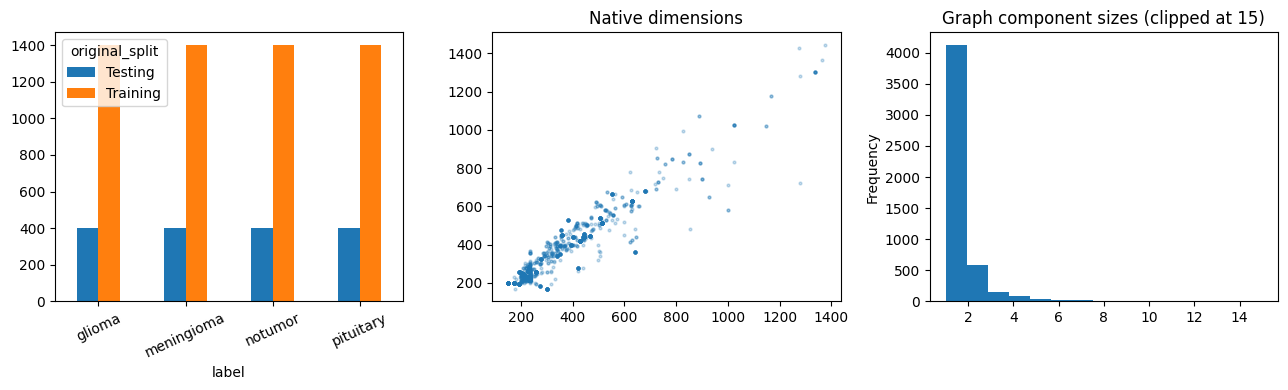

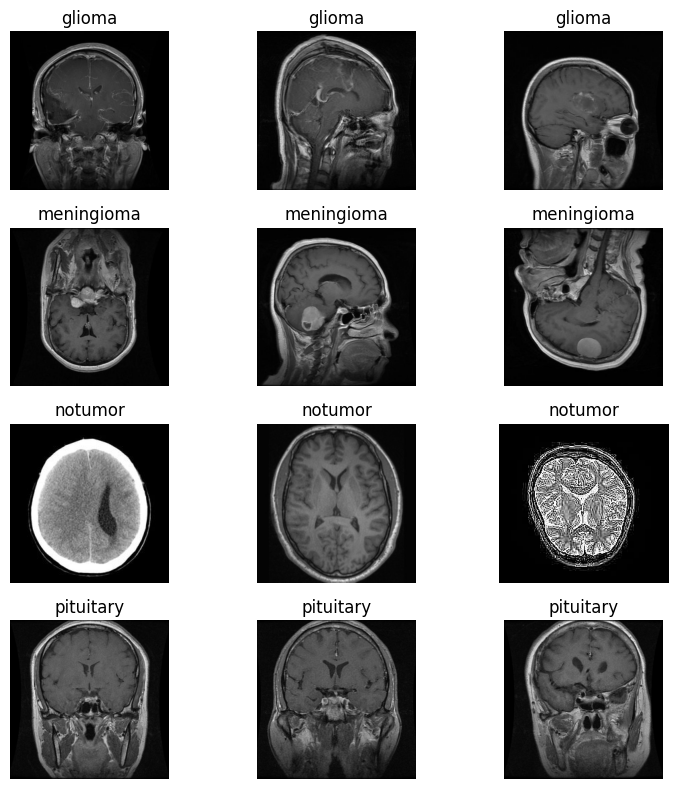

Device: cuda | training jobs: 24


In [21]:
DATA_ROOT=obtain_kaggle();RAW=scan_kaggle(DATA_ROOT)
GRAPH,CLEAN,EXACT,AUDIT=graph_audit(RAW);display(pd.DataFrame([AUDIT]))
CONDITIONS=create_kaggle_splits(GRAPH,CLEAN,EXACT)
counts=pd.concat([pd.DataFrame([dict(condition=c,split=s,label=label,n=len(f[f.label==label])) for s,f in splits.items() for label in CLASSES]) for c,splits in CONDITIONS.items()])
counts.to_csv(OUT/'eda_split_counts.csv',index=False);display(counts)
fig,axes=plt.subplots(1,3,figsize=(13,4))
pd.crosstab(RAW.label,RAW.original_split).plot.bar(ax=axes[0],rot=25)
axes[1].scatter(RAW.width,RAW.height,s=4,alpha=.25);axes[1].set_title('Native dimensions')
GRAPH.groupby('split_group').size().clip(upper=15).plot.hist(bins=15,ax=axes[2]);axes[2].set_title('Graph component sizes (clipped at 15)')
savefig(fig,'kaggle_eda')
fig,axes=plt.subplots(K,3,figsize=(8,K*2),squeeze=False)
for c in range(K):
    for ax,(_,r) in zip(axes[c],CONDITIONS['audited']['train'].query('label_id == @c').head(3).iterrows()):
        with Image.open(r.path) as im:ax.imshow(im.convert('RGB'))
        ax.set_title(CLASSES[c]);ax.axis('off')
savefig(fig,'audited_training_examples')
PROTOCOL=dict(version=VERSION,engine_signature=ENGINE_SIGNATURE,task=1,profile=PROFILE,cfg=CFG,models=MODEL_NAMES,run_matched_replay=RUN_MATCHED_REPLAY,
    audit=AUDIT,release_fingerprint=digest(RAW[['relative_path','file_sha256']].to_dict('records')),
    splits={c:{s:digest(f.sample_id.tolist()) for s,f in splits.items()} for c,splits in CONDITIONS.items()},
    note='No verified Kaggle patient IDs. Exact-only replay is a deliberately leakage-prone diagnostic, excluded from new headline results.')
PROTOCOL_SHA=digest(PROTOCOL);OUT_PROTOCOL=OUT/'protocol.json'
if OUT_PROTOCOL.exists():assert json.loads(OUT_PROTOCOL.read_text())==json.loads(json.dumps(PROTOCOL,default=json_default)), 'Configuration changed: use a new RUN_NAME.'
write_json(OUT_PROTOCOL,PROTOCOL);write_json(OUT/'math_checks.json',verify_six_qubits())
print('Device:',DEVICE,'| training jobs:',len(CONDITIONS)*len(MODEL_NAMES)*len(CFG['seeds']))


## Train audited models, then optional matched exact-only replay

In [22]:
RESULTS=[]
for condition in CONDITIONS:
    for name in MODEL_NAMES:
        for seed in CFG['seeds']:RESULTS.append(train_image_model(name,condition,CONDITIONS[condition],seed))
RESULTS=pd.DataFrame(RESULTS);RESULTS.to_csv(OUT/'results_by_seed.csv',index=False);display(RESULTS)


Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:01<00:00, 208MB/s]  


audited ViT_B16 s42 epoch1:   0%|          | 0/434 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: Memory Efficient attention defaults to a non-deterministic algorithm. To explicitly enable determinism call torch.use_deterministic_algorithms(True, warn_only=False). (Triggered internally at /pytorch/aten/src/ATen/native/transformers/cuda/attention_backward.cu:900.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


audited ViT_B16 seed 42 epoch 1 validation F1 0.9258


audited ViT_B16 s42 epoch2:   0%|          | 0/434 [00:00<?, ?it/s]

... (1,141 outputs left out)

exact_only_replay CNNControl s29 epoch20:   0%|          | 0/139 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: adaptive_avg_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


exact_only_replay CNNControl seed 29 epoch 20 validation F1 0.8605


,protocol_sha256,condition,model,seed,selected_epoch,parameters,seconds,accuracy,balanced_accuracy,macro_f1,nll,macro_auc
0,fa4d8d2c05ce2446bd3064ad4631cc9955de84f6074a0c...,audited,ViT_B16,42,19,85801732,1506.435698,0.947066,0.945718,0.945884,0.241644,0.990330
1,fa4d8d2c05ce2446bd3064ad4631cc9955de84f6074a0c...,audited,ViT_B16,13,12,85801732,1284.526002,0.942602,0.941388,0.941836,0.248591,0.986379
2,fa4d8d2c05ce2446bd3064ad4631cc9955de84f6074a0c...,audited,ViT_B16,29,14,85801732,1439.270937,0.946429,0.945000,0.945027,0.252791,0.977591
3,fa4d8d2c05ce2446bd3064ad4631cc9955de84f6074a0c...,audited,Swin_T,42,13,27522430,1197.568801,0.938776,0.937323,0.937758,0.256853,0.983663
4,fa4d8d2c05ce2446bd3064ad4631cc9955de84f6074a0c...,audited,Swin_T,13,18,27522430,1331.314227,0.939413,0.937905,0.938140,0.247439,0.988235
5,fa4d8d2c05ce2446bd3064ad4631cc9955de84f6074a0c...,audited,Swin_T,29,13,27522430,1182.201387,0.943240,0.941858,0.941946,0.245942,0.986681
6,fa4d8d2c05ce2446bd3064ad4631cc9955de84f6074a0c...,audited,HybridCNN,42,19,89350,277.158297,0.757653,0.754721,0.750003,0.781820,0.898721
7,fa4d8d2c05ce2446bd3064ad4631cc9955de84f6074a0c...,audited,HybridCNN,13,20,89350,274.275033,0.733418,0.730685,0.724278,0.797906,0.892144
8,fa4d8d2c05ce2446bd3064ad4631cc9955de84f6074a0c...,audited,HybridCNN,29,20,89350,273.126485,0.754464,0.751664,0.744328,0.815625,0.898550
9,fa4d8d2c05ce2446bd3064ad4631cc9955de84f6074a0c...,audited,CNNControl,42,19,89356,183.003918,0.709821,0.706601,0.692982,0.842882,0.872700


## Training curves from the fixed first seed

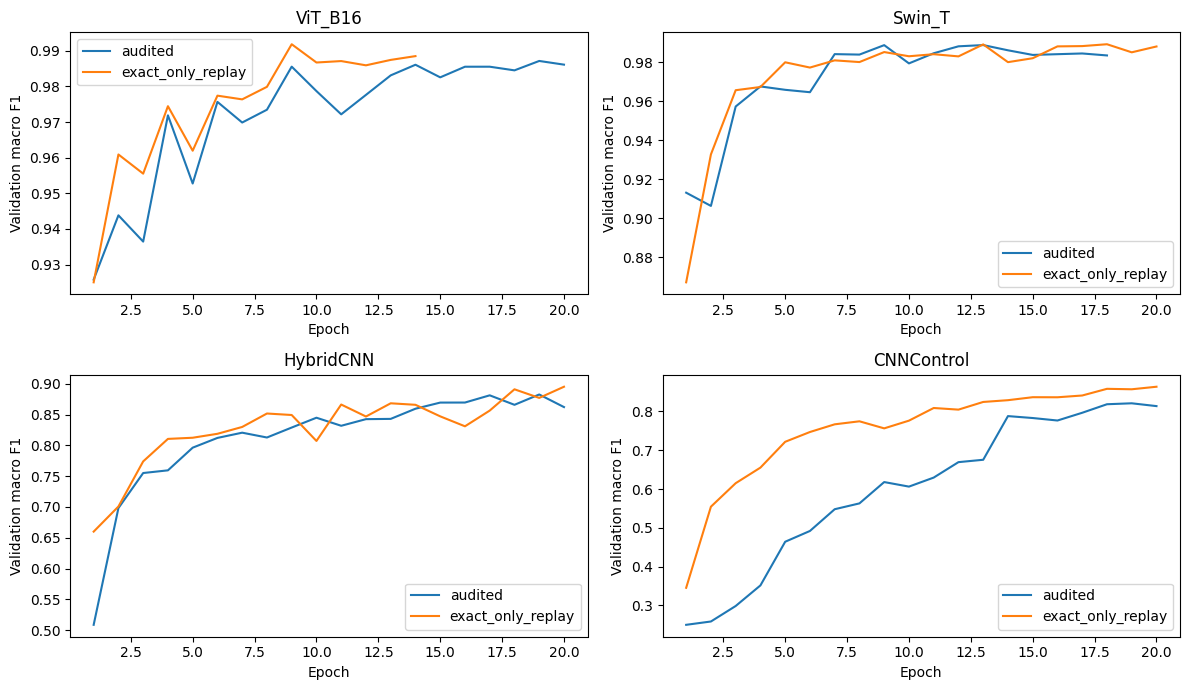

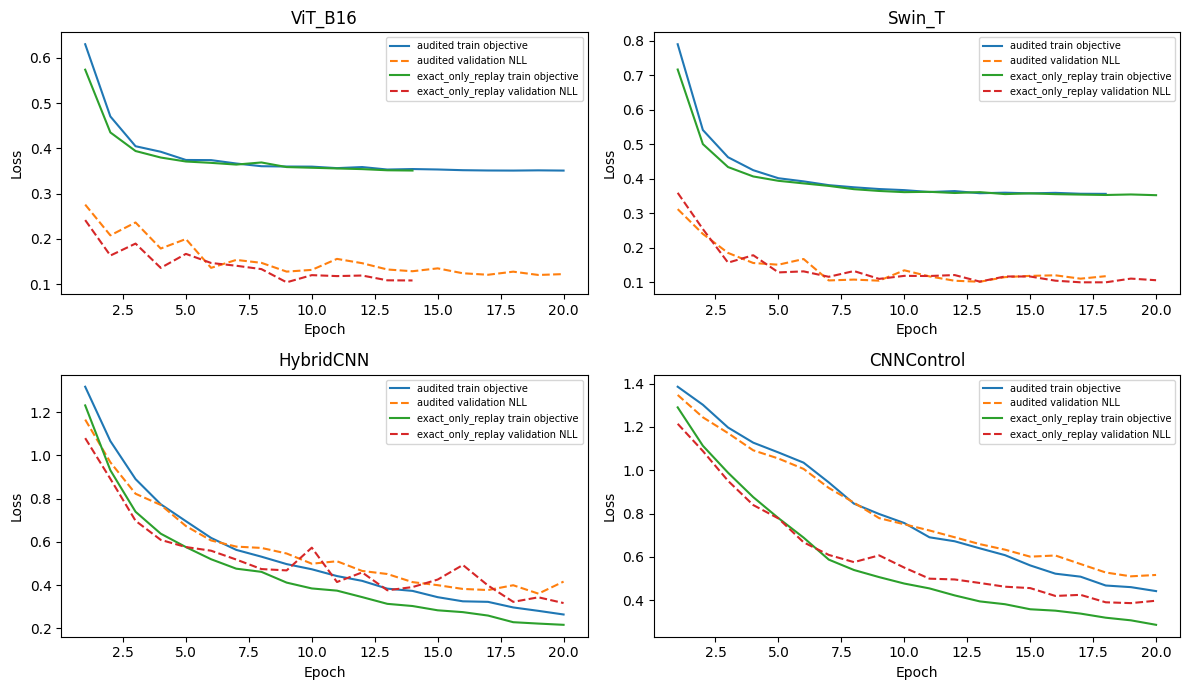

In [23]:
fig,axes=plt.subplots(2,2,figsize=(12,7))
for ax,name in zip(axes.ravel(),MODEL_NAMES):
    for condition in CONDITIONS:
        h=pd.read_csv(OUT/condition/name/f'seed_{CFG["seeds"][0]}'/'history.csv')
        ax.plot(h.epoch,h.validation_f1,label=condition)
    ax.set_title(name);ax.set_xlabel('Epoch');ax.set_ylabel('Validation macro F1');ax.legend()
savefig(fig,'validation_training_curves')
fig,axes=plt.subplots(2,2,figsize=(12,7))
for ax,name in zip(axes.ravel(),MODEL_NAMES):
    for condition in CONDITIONS:
        h=pd.read_csv(OUT/condition/name/f'seed_{CFG["seeds"][0]}'/'history.csv')
        ax.plot(h.epoch,h.train_loss,label=condition+' train objective')
        ax.plot(h.epoch,h.validation_nll,ls='--',label=condition+' validation NLL')
    ax.set_title(name);ax.set_xlabel('Epoch');ax.set_ylabel('Loss');ax.legend(fontsize=7)
savefig(fig,'loss_training_curves')


## Historical and new accuracy side by side

In [24]:
historical={'ViT_B16':(94.36,1579,'7200 release; exact-only cleaning'),
            'Swin_T':(92.91,1579,'7200 release; exact-only cleaning'),
            'HybridCNN':(87.04,1281,'7023 release; different original test set'),
            'CNNControl':(80.17,1281,'7023 release; different original test set')}
rows=[]
for name in MODEL_NAMES:
    new=RESULTS[(RESULTS.condition=='audited')&(RESULTS.model==name)];old,n,source=historical[name]
    seed42=new[new.seed==42].iloc[0]
    rows.append(dict(model=name,historical_reported_accuracy_pct=old,historical_test_n=n,historical_protocol=source,
        new_audited_seed42_accuracy_pct=100*seed42.accuracy,new_audited_mean_accuracy_pct=100*new.accuracy.mean(),
        new_seed_accuracy_sd_pp=100*new.accuracy.std(ddof=1) if len(new)>1 else 0,new_test_n=len(CONDITIONS['audited']['test']),
        descriptive_difference_from_historical_pp=100*new.accuracy.mean()-old,
        historical_comparison_is_paired=False,interpretation='Historical comparison changes the test set and, for CNNs, the release. Use matched replay for an audit-specific contrast.'))
HISTORICAL_TABLE=pd.DataFrame(rows);HISTORICAL_TABLE.to_csv(OUT/'historical_vs_audited_accuracy.csv',index=False);display(HISTORICAL_TABLE.round(3))


,model,historical_reported_accuracy_pct,historical_test_n,historical_protocol,new_audited_seed42_accuracy_pct,new_audited_mean_accuracy_pct,new_seed_accuracy_sd_pp,new_test_n,descriptive_difference_from_historical_pp,historical_comparison_is_paired,interpretation
0,ViT_B16,94.36,1579,7200 release; exact-only cleaning,94.707,94.537,0.241,1568,0.177,False,Historical comparison changes the test set and...
1,Swin_T,92.91,1579,7200 release; exact-only cleaning,93.878,94.048,0.241,1568,1.138,False,Historical comparison changes the test set and...
2,HybridCNN,87.04,1281,7023 release; different original test set,75.765,74.851,1.317,1568,-12.189,False,Historical comparison changes the test set and...
3,CNNControl,80.17,1281,7023 release; different original test set,70.982,72.173,1.062,1568,-7.997,False,Historical comparison changes the test set and...


## Duplicate-group and seed uncertainty for the matched replay

In [25]:
matched=[]
if RUN_MATCHED_REPLAY:
    test=CONDITIONS['audited']['test'];groups=test[['split_group','label_id']].drop_duplicates().sort_values('split_group');rng=np.random.default_rng(414)
    for name in MODEL_NAMES:
        a=[];b=[]
        for seed in CFG['seeds']:
            pa=np.load(OUT/'audited'/name/f'seed_{seed}'/'predictions.npz');pb=np.load(OUT/'exact_only_replay'/name/f'seed_{seed}'/'predictions.npz')
            assert np.array_equal(pa['sample_id'],pb['sample_id']);a.append(pa['probability']);b.append(pb['probability'])
        a=np.stack(a);b=np.stack(b);y=test.label_id.to_numpy();preda=a.argmax(2);predb=b.argmax(2)
        observed=float(((preda==y).mean(1)-(predb==y).mean(1)).mean());draws=[]
        for _ in range(CFG['bootstrap']):
            selected=[]
            for c,g in groups.groupby('label_id'):
                gs=rng.choice(g.split_group.to_numpy(),len(g),replace=True)
                selected.extend(np.concatenate([np.flatnonzero(test.split_group.to_numpy()==u) for u in gs]))
            ix=np.asarray(selected,int);seeds=rng.integers(0,len(a),len(a))
            draws.append(float(np.mean([(preda[s,ix]==y[ix]).mean()-(predb[s,ix]==y[ix]).mean() for s in seeds])))
        lo,hi=np.quantile(draws,[.025,.975])
        matched.append(dict(model=name,exact_only_mean_accuracy_pct=100*np.mean((predb==y).mean(1)),audited_mean_accuracy_pct=100*np.mean((preda==y).mean(1)),
            audited_minus_exact_only_pp=observed*100,ci_low_pp=lo*100,ci_high_pp=hi*100,test_images=len(test),test_duplicate_groups=len(groups),
            interval_scope='paired seeds and duplicate groups conditional on the fitted split; patient independence unverified'))
MATCHED=pd.DataFrame(matched);MATCHED.to_csv(OUT/'same_release_same_test_audit_comparison.csv',index=False)
if len(MATCHED):display(MATCHED.round(3))


,model,exact_only_mean_accuracy_pct,audited_mean_accuracy_pct,audited_minus_exact_only_pp,ci_low_pp,ci_high_pp,test_images,test_duplicate_groups,interval_scope
0,ViT_B16,95.068,94.537,-0.531,-1.169,0.043,1568,1345,paired seeds and duplicate groups conditional ...
1,Swin_T,93.984,94.048,0.064,-0.511,0.619,1568,1345,paired seeds and duplicate groups conditional ...
2,HybridCNN,79.549,74.851,-4.698,-6.722,-2.779,1568,1345,paired seeds and duplicate groups conditional ...
3,CNNControl,75.914,72.173,-3.741,-5.538,-1.943,1568,1345,paired seeds and duplicate groups conditional ...


## Plots, classification reports and manuscript-ready result template

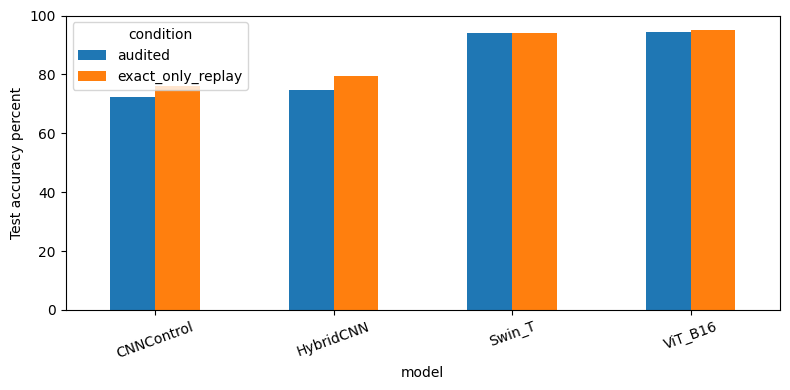

Results bundle: /kaggle/working/Task1_run1.zip


In [26]:
fig,ax=plt.subplots(figsize=(8,4));s=RESULTS.groupby(['condition','model']).accuracy.mean().unstack(0)*100
s.plot.bar(ax=ax,rot=20);ax.set_ylabel('Test accuracy percent');ax.set_ylim(0,100);savefig(fig,'old_replay_and_audited_accuracy')
for name in MODEL_NAMES:
    cp=np.load(OUT/'audited'/name/f'seed_{CFG["seeds"][0]}'/'predictions.npz');y,p=cp['truth'],cp['probability']
    report=classification_report(y,p.argmax(1),labels=range(K),target_names=CLASSES,zero_division=0,output_dict=True)
    write_json(OUT/f'classification_{name}.json',report)
    pd.DataFrame(confusion_matrix(y,p.argmax(1),labels=range(K)),index=CLASSES,columns=CLASSES).to_csv(OUT/f'confusion_{name}.csv')
lines=['# Task 1 results','', 'The near-duplicate graph was applied before splitting training and validation. Cross-label graph components were quarantined; official Testing components were retained on the test side; linked training images were excluded. Every audited graph component is confined to one partition.', '',
'The transformer architecture, augmentation, optimizer and training budget follow the original transformer notebook. The six-qubit hybrid and its bottleneck control follow the original 64-pixel CNN architecture, with an independently checked analytic statevector implementation. All four models use the same audited manifests.', '',
HISTORICAL_TABLE.to_markdown(index=False), '',
'Historical differences above are descriptive, because the old test sets differ and the old CNN study used another release. The following optional diagnostic retrains both cleaning conditions on the same 7200-image release and evaluates the same test images; it better isolates the effect of the audit. Its exact-only values are not new headline results.', '',MATCHED.to_markdown(index=False) if len(MATCHED) else 'Matched replay was disabled.', '',
'The result may rise or fall. Report the observed direction; do not assume an accuracy decrease. Duplicate groups are not verified patients. This is retrospective internal validation rather than an independent clinical cohort.']
if PROFILE=='smoke':lines.insert(1,'SYNTHETIC ENGINEERING CHECK — historical values are source quotations, all newly computed values are fixture results.')
(OUT/'TASK1_RESULTS.md').write_text('\n'.join(lines));write_json(OUT/'completion.json',dict(task=1,profile=PROFILE,protocol_sha256=PROTOCOL_SHA,completed_jobs=len(RESULTS)))
PACKAGE=package_outputs(OUT,'Task1_'+OUT.name)


## Outputs and reruns

All tables, plots, predictions, protocol records and model checkpoints are in the printed output directory. A ZIP is created at the end. Completed candidate/fold checkpoints are reused only with matching identities. In Colab, keep Google Drive enabled to continue after a runtime reset. Do not publish smoke-mode values.

Sources checked for this implementation: [native Figshare dataset](https://figshare.com/articles/dataset/brain_tumor_dataset/1512427), [nested CV documentation](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html), [ViT weights](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.vit_b_16.html), [Swin weights](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.swin_t.html). Model definitions and historical numbers are traced to the supplied paper and notebooks.